In [1]:
!pip install xgboost==2.1.4 -q

Mounted at /content/drive


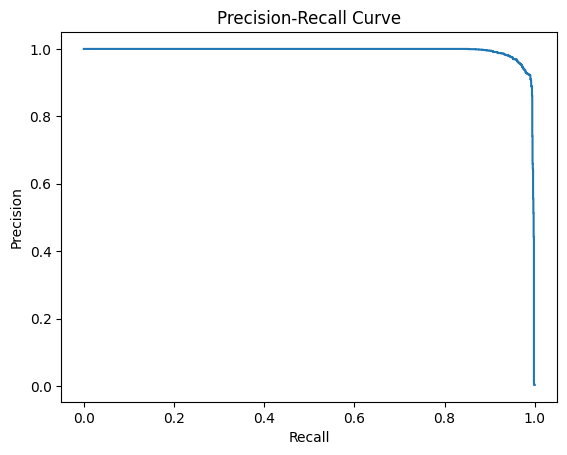

Best threshold: 0.993 | Precision: 0.9687 | Recall: 0.9598
              precision    recall  f1-score   support

           0     0.9999    0.9999    0.9999    552439
           1     0.9687    0.9598    0.9642      1643

    accuracy                         0.9998    554082
   macro avg     0.9843    0.9799    0.9821    554082
weighted avg     0.9998    0.9998    0.9998    554082



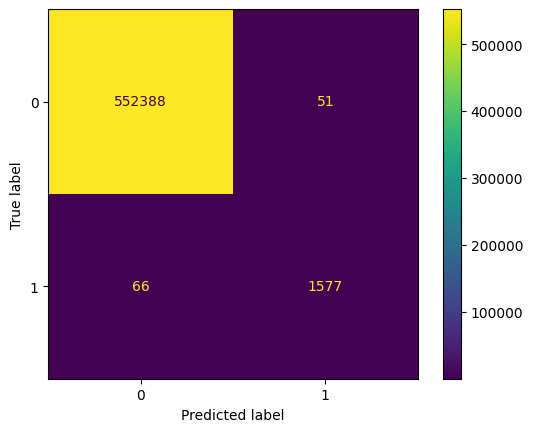

Final model saved ✅


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, ConfusionMatrixDisplay, classification_report

PATH = "/content/drive/MyDrive/fraud-detection"
X_train, X_test, y_train, y_test = joblib.load(f"{PATH}/data/split.pkl")
model = joblib.load(f"{PATH}/models/xgb.pkl")
proba = model.predict_proba(X_test)[:, 1]

# 1. منحنى Precision-Recall
p, r, t = precision_recall_curve(y_test, proba)
plt.plot(r, p)
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall Curve")
plt.savefig(f"{PATH}/figures/05_pr_curve.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. أحسن Threshold
f1 = 2 * p * r / (p + r + 1e-9)
best_idx = np.argmax(f1[:-1])
best_thr = float(t[best_idx])
print(f"Best threshold: {best_thr:.3f} | Precision: {p[best_idx]:.4f} | Recall: {r[best_idx]:.4f}")

# 3. التقرير والـ Confusion Matrix
pred = (proba >= best_thr).astype(int)
print(classification_report(y_test, pred, digits=4))
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.savefig(f"{PATH}/figures/06_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# 4. حفظ الموديل النهائي
joblib.dump({"model": model, "threshold": best_thr, "features": list(X_train.columns)},
            f"{PATH}/models/fraud_model.pkl")
print("Final model saved ✅")